## Params

In [ ]:
FEATURES = ["Recency", "Frequency", "Monetary"]
PCA_VAR = 0.95
RANDOM_STATE = 42
N_INIT = 10
MAX_ITER = 300
TOL = 1e-3
REG_COVAR = 1e-6
INIT_PARAMS = "kmeans"
K_RANGE = range(2, 11)
COV_TYPES = ["full", "tied", "diag", "spherical"]
MIN_CLUSTER_FRAC = 0.01

## Import thư viện và đọc dữ liệu

In [ ]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

warnings.filterwarnings("ignore", category=UserWarning)

def find(rel):
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figure"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"})
X = df[FEATURES].copy()
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()
print("Dữ liệu đầu vào:", X.shape)

**Nhận xét so với A01 K-Means:** A04 GMM sử dụng cùng tập 4.327 khách hàng và ba
đặc trưng Recency, Frequency, Monetary như A01. Cả hai đều không biến đổi log1p,
dùng StandardScaler, seed 42 và n_init=10. Vì vậy, dữ liệu đầu vào và một số
thiết lập được giữ thống nhất để thuận tiện đối chiếu.

Khác biệt nằm ở thuật toán, ngưỡng PCA và quy tắc chọn cấu hình. A01 dùng K-Means,
PCA ngưỡng 90% và chọn k theo Silhouette cao nhất. A04 dùng GMM, tăng ngưỡng PCA
lên 95%, khảo sát thêm bốn dạng hiệp phương sai và chọn BIC thấp nhất trong các
cấu hình hội tụ, có cụm nhỏ nhất đạt ít nhất 1% số khách. Ngưỡng PCA cao hơn
không nhất thiết làm số thành phần tăng; cần xem số PC thực giữ lại ở bước sau.
Các khác biệt này chưa đủ để kết luận A04 tốt hơn A01; cần đối chiếu kết quả
phân cụm và hồ sơ RFM sau khi chạy mô hình.

## chuẩn hóa và PCA 95%

In [5]:
X_t = X.copy()

X_scaled = StandardScaler().fit_transform(X_t)
cum = np.cumsum(PCA(svd_solver="full").fit(X_scaled).explained_variance_ratio_)
n_pc = int(np.searchsorted(cum, PCA_VAR) + 1)
pca = PCA(n_components=n_pc, svd_solver="full").fit(X_scaled)
Z = pca.transform(X_scaled)
print("Phương sai tích lũy:", cum.round(4))
print(f"Số PC giữ lại: {n_pc} / {len(FEATURES)} (phương sai giữ {cum[n_pc-1]:.2%})")

Phương sai tích lũy: [0.5638 0.8655 1.    ]
Số PC giữ lại: 3 / 3 (phương sai giữ 100.00%)


## Quét k × covariance_type

Chọn: full, k=5, BIC=718.9, Silhouette=0.1349, cụm nhỏ nhất=49


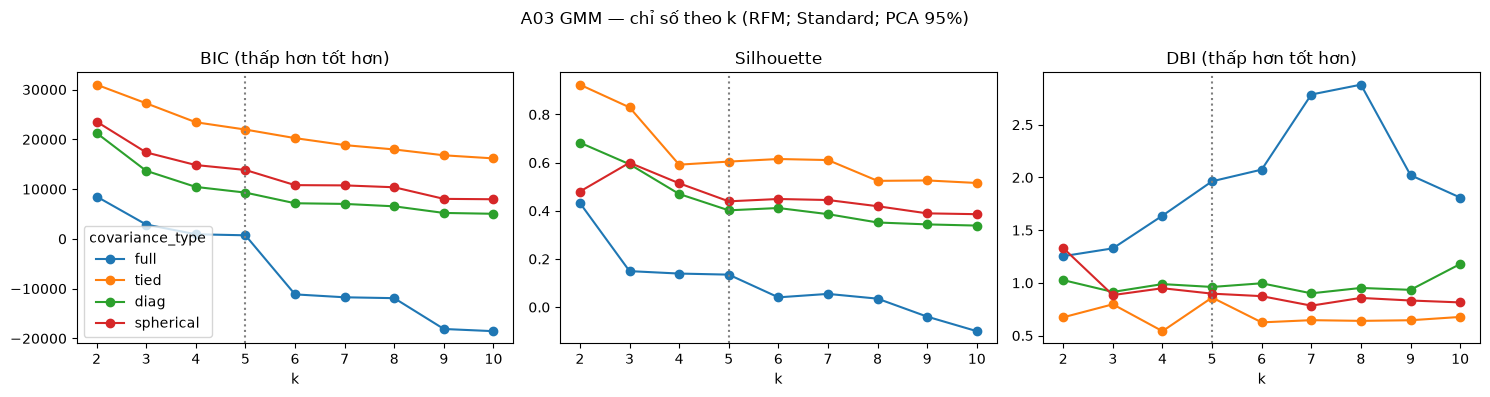

In [7]:
def sweep(Zs):
    rows = []
    for cov in COV_TYPES:
        for k in K_RANGE:
            gm = GaussianMixture(n_components=k, covariance_type=cov, n_init=N_INIT, max_iter=MAX_ITER, tol=TOL,
                                  reg_covar=REG_COVAR, init_params=INIT_PARAMS, random_state=RANDOM_STATE).fit(Zs)
            lab = gm.predict(Zs); sizes = np.bincount(lab, minlength=k)
            ok = len(np.unique(lab)) > 1
            rows.append({"covariance_type": cov, "k": k, "BIC": gm.bic(Zs), "AIC": gm.aic(Zs),
                         "Silhouette": silhouette_score(Zs, lab) if ok else np.nan,
                         "DBI": davies_bouldin_score(Zs, lab) if ok else np.nan,
                         "CHI": calinski_harabasz_score(Zs, lab) if ok else np.nan,
                         "min_cluster": int(sizes.min()), "converged": bool(gm.converged_)})
    return pd.DataFrame(rows)

def select(res, n):
    ok = res[res["converged"] & (res["min_cluster"] >= MIN_CLUSTER_FRAC * n)]
    return ok.loc[ok["BIC"].idxmin()]

res = sweep(Z)
best = select(res, len(X))
print(f"Chọn: {best['covariance_type']}, k={int(best['k'])}, BIC={best['BIC']:,.1f}, "
      f"Silhouette={best['Silhouette']:.4f}, cụm nhỏ nhất={int(best['min_cluster'])}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["BIC", "Silhouette", "DBI"]):
    for cov in COV_TYPES:
        s = res[res["covariance_type"] == cov]
        ax.plot(s["k"], s[col], marker="o", label=cov)
    ax.axvline(int(best["k"]), color="gray", ls=":")
    ax.set_xlabel("k"); ax.set_title(col + (" (thấp hơn tốt hơn)" if col in ("BIC", "DBI") else ""))
axes[0].legend(title="covariance_type")
plt.suptitle("A03 GMM — chỉ số theo k (RFM; Standard; PCA 95%)")
plt.tight_layout(); plt.savefig(FIG / "gmm_metrics.png", dpi=150); plt.show()

* BIC: dạng full có BIC thấp nhất và tiếp tục giảm khi k tăng, cho thấy tiêu chí này ưu tiên mô hình phức tạp hơn trong phạm vi khảo sát. Tuy nhiên, cấu hình được chọn phải đồng thời hội tụ và có cụm nhỏ nhất đạt ít nhất 1% số khách; không thể chỉ chọn theo điểm BIC thấp nhất trên hình.
* Silhouette: dạng tied nhìn chung đạt điểm cao nhất, đặc biệt tại k=2–3. Dạng full có Silhouette thấp từ k=3 và âm tại k=9–10, cho thấy việc tăng số thành phần không giúp các cụm tách biệt rõ hơn theo khoảng cách.
* DBI: dạng tied thường có DBI thấp nhất, còn full có DBI cao ở phần lớn cấu hình. Kết hợp với Silhouette, kết quả gợi ý tied tạo các cụm tách biệt hơn, dù BIC không thấp bằng full.
* Tại k=5 được đánh dấu, dạng full có Silhouette khoảng 0,13 và DBI khoảng 1,96. Vì vậy, nếu đây là cấu hình được chọn theo BIC và các điều kiện đặt trước, cần ghi nhận rằng các cụm vẫn chồng lấn đáng kể. Cần xem thêm quy mô và hồ sơ RFM để đánh giá ý nghĩa phân khúc khách hàng.

## Train mô hình cuối

In [8]:
model = Pipeline([("scaler", StandardScaler()),
                   ("pca", PCA(n_components=n_pc, svd_solver="full")),
                   ("gmm", GaussianMixture(n_components=int(best["k"]), covariance_type=best["covariance_type"],
                                            n_init=N_INIT, max_iter=MAX_ITER, tol=TOL, reg_covar=REG_COVAR,
                                            init_params=INIT_PARAMS, random_state=RANDOM_STATE))]).fit(X_t)
gm = model["gmm"]
labels = gm.predict(Z)
proba = gm.predict_proba(Z)
assert (model[:-1].transform(X_t) == Z).all()
print("Hội tụ:", gm.converged_, "| số vòng EM:", gm.n_iter_)
print(pd.Series(labels).value_counts().sort_index().rename("Số khách"))
print("Silhouette:", round(silhouette_score(Z, labels), 4), "| DBI:", round(davies_bouldin_score(Z, labels), 4))

Hội tụ: True | số vòng EM: 13
0    2129
1    1536
2     503
3     110
4      49
Name: Số khách, dtype: int64
Silhouette: 0.1349 | DBI: 1.9633


**Nhận xét:** đạt Silhouette 0,1349, cho thấy các cụm chưa tách biệt rõ. Cần kết hợp quy mô và hồ sơ RFM từng cụm để đánh giá ý nghĩa phân khúc khách hàng; chưa đủ cơ sở kết luận mô hình phân cụm tốt.

## Hồ sơ cụm

In [9]:
prof = X.assign(cluster=labels).groupby("cluster").agg(
    customers=("Monetary", "size"), Recency=("Recency", "median"),
    Frequency=("Frequency", "median"), Monetary=("Monetary", "median"),
    Monetary_sum=("Monetary", "sum"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof.drop(columns="Monetary_sum").round(1)

,customers,Recency,Frequency,Monetary,customer_share_pct,Monetary_share_pct
cluster,,,,,,
0,2129,117.0,1.0,304.6,49.2,8.6
1,1536,26.0,4.0,1290.6,35.5,27.2
2,503,58.0,6.0,3596.3,11.6,23.2
3,110,3.0,21.0,7958.6,2.5,15.8
4,49,11.0,25.0,19766.6,1.1,25.2


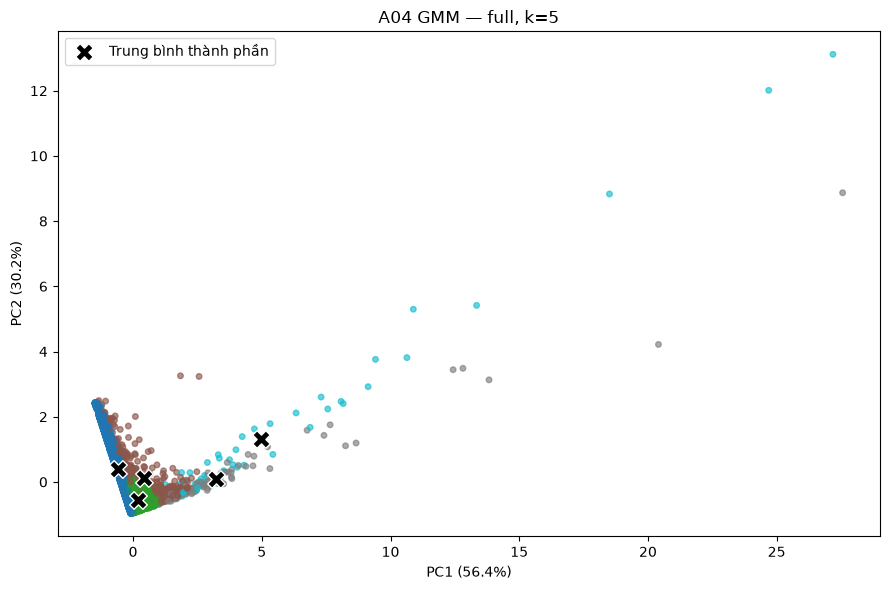

In [10]:
fig, ax = plt.subplots(figsize=(9, 6))
centers = gm.means_
sc = ax.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=16, alpha=0.65)
ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=160, edgecolors="white", label="Trung bình thành phần")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title(f"A04 GMM — {best['covariance_type']}, k={int(best['k'])}")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "gmm_clusters_pca.png", dpi=150); plt.show()

**Nhận xét:** Với cấu hình GMM full, k=5, phần lớn khách hàng tập trung gần gốc tọa độ, các cụm nằm sát nhau và chồng lấn đáng kể. Một số điểm trải dài về phía PC1 và PC2 dương lớn, thể hiện những khách hàng có đặc trưng khác biệt so với phần đông. Các dấu X biểu diễn trung bình của từng thành phần Gaussian.
Hai trục PCA hiển thị khoảng 86,6% tổng phương sai, nên hình chưa thể hiện toàn bộ không gian mô hình sử dụng. Tuy vậy, mức chồng lấn quan sát được phù hợp với Silhouette khoảng 0,1349, cho thấy các cụm chưa tách biệt rõ. Cần đối chiếu thêm trung vị RFM và quy mô từng cụm trước khi đặt tên hoặc kết luận về giá trị khách hàng.

## Lưu kết quả

In [11]:
res.to_csv(OUT / 'gmm_a04_grid.csv', index=False)
pd.DataFrame({'CustomerID': df['CustomerID'], 'cluster': labels, 'max_proba': proba.max(axis=1).round(4)}) \
    .to_csv(OUT / 'gmm_a04_labels.csv', index=False)
joblib.dump(model, 'gmm_a04_model.pkl')
params = {
    'experiment': 'A04-GMM', 'features': FEATURES, 'log_cols': [], 'scaler': 'StandardScaler',
    'pca_variance': PCA_VAR, 'n_components': n_pc, 'pca_variance_kept': float(cum[n_pc - 1]),
    'covariance_type': best['covariance_type'], 'k': int(best['k']), 'bic': float(best['BIC']),
    'silhouette': float(silhouette_score(Z, labels)), 'dbi': float(davies_bouldin_score(Z, labels)),
}
with (OUT / 'gmm_a04_params.json').open('w', encoding='utf8') as f:
    json.dump(params, f, ensure_ascii=False, indent=2)
print('Đã lưu kết quả A04 vào:', OUT.resolve())

Đã lưu kết quả A04 vào: D:\DOAN\SGU-ML-High-Value-Customer-Prediction\project\notebooks\03_clustering_eval\17-11-2026_hieu_gmm_a04\data
